In [1]:
import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!pip install -q kaggle

In [3]:
print("Colab is running!")

Colab is running!


In [4]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"mokshithguptha123","key":"77d6831b400ab92c9fa76bc6c07ab7c5"}'}

In [5]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [6]:
!kaggle datasets list -s casia

ref                                                          title                                                  size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-----------------------------------------------------------  ----------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
debarghamitraroy/casia-webface                               CASIA-WebFace                                    2894308039  2025-12-22 13:28:48.327000           6852         34                1  
sophatvathana/casia-dataset                                  casia dataset                                    5600476572  2018-10-04 04:10:13.540000          18443        156           0.3125  
sondosaabed/casia-iris-thousand                              CASIA-Iris-Thousand                               514629968  2024-06-14 17:35:40.447000           4604         24                1  
monareyhanii/casia-iris-syn   

In [7]:
!kaggle datasets download -d divg07/casia-20-image-tampering-detection-dataset

Dataset URL: https://www.kaggle.com/datasets/divg07/casia-20-image-tampering-detection-dataset
License(s): unknown
100% 2.56G/2.56G [02:32<00:00, 18.0MB/s]



In [8]:
!ls


casia-20-image-tampering-detection-dataset.zip	kaggle.json  sample_data


In [9]:
!unzip -q casia-20-image-tampering-detection-dataset.zip

In [10]:
!ls


CASIA2						kaggle.json
casia-20-image-tampering-detection-dataset.zip	sample_data


In [11]:
!find . -maxdepth 3 -type d

.
./.config
./.config/configurations
./.config/logs
./.config/logs/2026.10.21
./CASIA2
./CASIA2/Au
./CASIA2/Tp
./CASIA2/CASIA 2 Groundtruth
./sample_data


In [12]:
import os

for root, dirs, files in os.walk("/content"):
    if len(files) > 100:
        print(root, len(files))

/content/CASIA2/Au 7492
/content/CASIA2/Tp 5125
/content/CASIA2/CASIA 2 Groundtruth 5123


In [13]:
import os

os.makedirs("/content/dataset/authentic", exist_ok=True)
os.makedirs("/content/dataset/forged", exist_ok=True)

print("Folders Created")

Folders Created


In [14]:
import os
import shutil

src = "/content/CASIA2/Au"
dst = "/content/dataset/authentic"

count = 0

for file in os.listdir(src):
    shutil.copy(
        os.path.join(src,file),
        os.path.join(dst,file)
    )
    count += 1

print("Copied:",count)

Copied: 7492


In [15]:
import os
import shutil

src = "/content/CASIA2/Tp"
dst = "/content/dataset/forged"

count = 0

for file in os.listdir(src):
    shutil.copy(
        os.path.join(src,file),
        os.path.join(dst,file)
    )
    count += 1

print("Copied:",count)

Copied: 5125


In [16]:
import os

auth_count = len(
    os.listdir("/content/dataset/authentic")
)

forged_count = len(
    os.listdir("/content/dataset/forged")
)

print("Authentic:",auth_count)
print("Forged:",forged_count)

Authentic: 7492
Forged: 5125


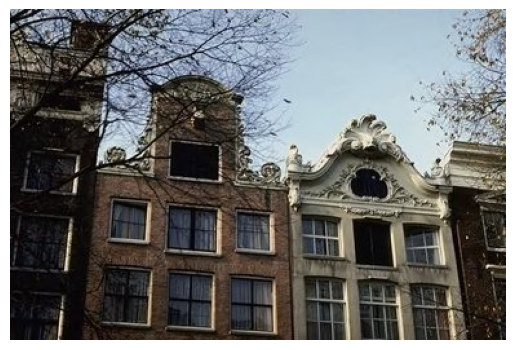

In [17]:
import cv2
import os
import matplotlib.pyplot as plt

auth_img = os.listdir(
    "/content/dataset/authentic"
)[0]

img = cv2.imread(
    "/content/dataset/authentic/"+auth_img
)

img = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

plt.imshow(img)
plt.axis("off")
plt.show()

In [18]:
# ==========================================
# PHASE 3.1 - IMPORT LIBRARIES
# ==========================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [19]:
# ==========================================
# PHASE 3.2 - PROJECT SETTINGS
# ==========================================

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.20
SEED = 42

DATASET_PATH = "/content/dataset"

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Validation split:", VALIDATION_SPLIT)

Image size: (224, 224)
Batch size: 32
Validation split: 0.2


In [20]:
# ==========================================
# PHASE 3.3 - CHECK DATASET
# ==========================================

authentic_path = os.path.join(
    DATASET_PATH,
    "authentic"
)

forged_path = os.path.join(
    DATASET_PATH,
    "forged"
)

print("Authentic folder exists:",
      os.path.exists(authentic_path))

print("Forged folder exists:",
      os.path.exists(forged_path))

print(
    "Authentic images:",
    len(os.listdir(authentic_path))
)

print(
    "Forged images:",
    len(os.listdir(forged_path))
)

Authentic folder exists: True
Forged folder exists: True
Authentic images: 7492
Forged images: 5125


In [21]:
# ==========================================
# PHASE 3.4 - TRAINING DATA GENERATOR
# ==========================================

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,

    # Small image transformations
    rotation_range=10,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,

    horizontal_flip=True,

    # 20% of images are used for validation
    validation_split=VALIDATION_SPLIT
)

train_generator = train_datagen.flow_from_directory(
    DATASET_PATH,

    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,

    class_mode="binary",

    subset="training",

    shuffle=True,
    seed=SEED
)

Found 10092 images belonging to 2 classes.


In [22]:
# ==========================================
# PHASE 3.5 - VALIDATION DATA GENERATOR
# ==========================================

validation_generator = train_datagen.flow_from_directory(
    DATASET_PATH,

    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,

    class_mode="binary",

    subset="validation",

    shuffle=False,
    seed=SEED
)

Found 2522 images belonging to 2 classes.


In [23]:
# ==========================================
# PHASE 3.6 - CHECK CLASS LABELS
# ==========================================

print("Class mapping:")
print(train_generator.class_indices)

Class mapping:
{'authentic': 0, 'forged': 1}


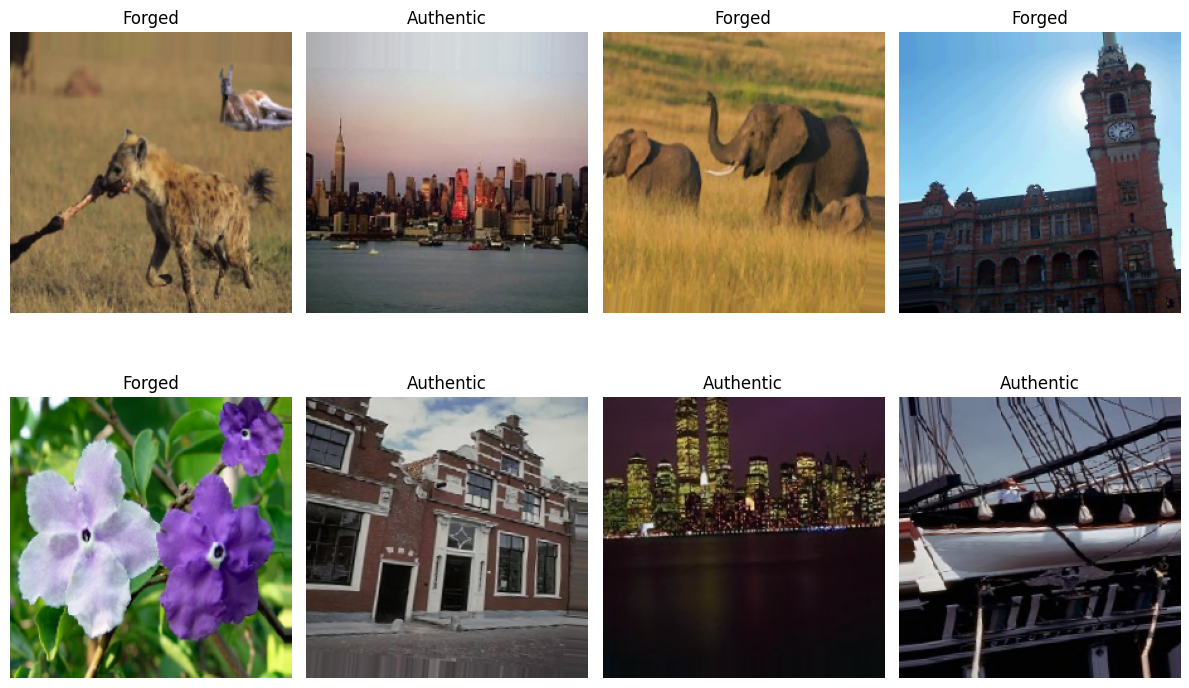

In [24]:
# ==========================================
# PHASE 3.7 - DISPLAY SAMPLE IMAGES
# ==========================================

images, labels = next(train_generator)

plt.figure(figsize=(12, 8))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i])

    if labels[i] == 0:
        title = "Authentic"
    else:
        title = "Forged"

    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
# ==========================================
# PHASE 3.8 - LOAD EFFICIENTNETB0
# ==========================================

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("EfficientNetB0 loaded successfully.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
EfficientNetB0 loaded successfully.


In [26]:
# ==========================================
# PHASE 3.9 - FREEZE PRETRAINED MODEL
# ==========================================

base_model.trainable = False

print("Base model frozen.")

Base model frozen.


In [27]:
# ==========================================
# PHASE 3.10 - BUILD CLASSIFICATION HEAD
# ==========================================

x = base_model.output

# Convert feature maps into one feature vector
x = GlobalAveragePooling2D()(x)

# Reduce overfitting
x = Dropout(0.30)(x)

# Binary output:
# 0 = Authentic
# 1 = Forged
output = Dense(
    1,
    activation="sigmoid"
)(x)

model = Model(
    inputs=base_model.input,
    outputs=output
)

print("Model created.")

Model created.


In [28]:
# ==========================================
# PHASE 3.11 - COMPILE MODEL
# ==========================================

model.compile(
    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print("Model compiled.")

Model compiled.


In [29]:
# ==========================================
# PHASE 3.12 - MODEL SUMMARY
# ==========================================

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [30]:
# ==========================================
# PHASE 3.13 - TRAINING CALLBACKS
# ==========================================

checkpoint = ModelCheckpoint(
    "/content/best_forgery_model.keras",

    monitor="val_accuracy",

    save_best_only=True,

    mode="max",

    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",

    patience=5,

    restore_best_weights=True,

    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",

    factor=0.5,

    patience=2,

    min_lr=1e-7,

    verbose=1
)

print("Callbacks ready.")

Callbacks ready.


In [31]:
# ==========================================
# PHASE 3.14 - FINAL CHECK
# ==========================================

print("================================")
print("PHASE 3 COMPLETE")
print("================================")

print("Training images:",
      train_generator.samples)

print("Validation images:",
      validation_generator.samples)

print("Classes:",
      train_generator.class_indices)

print("Image size:",
      IMAGE_SIZE)

print("Batch size:",
      BATCH_SIZE)

print("Model:",
      "EfficientNetB0")

print("Optimizer:",
      "Adam")

print("Loss:",
      "Binary Crossentropy")

print("================================")
print("READY FOR TRAINING")
print("================================")

PHASE 3 COMPLETE
Training images: 10092
Validation images: 2522
Classes: {'authentic': 0, 'forged': 1}
Image size: (224, 224)
Batch size: 32
Model: EfficientNetB0
Optimizer: Adam
Loss: Binary Crossentropy
READY FOR TRAINING


In [32]:
# ============================================================
# PHASE 4A.1 - IMPORTS
# ============================================================

import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers
from tensorflow.keras import Model

from tensorflow.keras.applications import EfficientNetB0

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    ReduceLROnPlateau
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [33]:
# ============================================================
# PHASE 4A.2 - DATASET PATHS
# ============================================================

CASIA_PATH = "/content/CASIA2"

AUTHENTIC_PATH = os.path.join(
    CASIA_PATH,
    "Au"
)

FORGED_PATH = os.path.join(
    CASIA_PATH,
    "Tp"
)

print("Authentic path:")
print(AUTHENTIC_PATH)

print("\nForged path:")
print(FORGED_PATH)

print("\nAuthentic folder exists:",
      os.path.exists(AUTHENTIC_PATH))

print("Forged folder exists:",
      os.path.exists(FORGED_PATH))

Authentic path:
/content/CASIA2/Au

Forged path:
/content/CASIA2/Tp

Authentic folder exists: True
Forged folder exists: True


In [34]:
# ============================================================
# PHASE 4A.3 - COUNT DATASET FILES
# ============================================================

authentic_files = [
    f for f in os.listdir(AUTHENTIC_PATH)
    if os.path.isfile(
        os.path.join(AUTHENTIC_PATH, f)
    )
]

forged_files = [
    f for f in os.listdir(FORGED_PATH)
    if os.path.isfile(
        os.path.join(FORGED_PATH, f)
    )
]

print("Authentic files:", len(authentic_files))
print("Forged files:", len(forged_files))

Authentic files: 7492
Forged files: 5125


In [35]:
# ============================================================
# PHASE 4A.4 - CHECK IMAGE EXTENSIONS
# ============================================================

from collections import Counter

auth_extensions = Counter(
    os.path.splitext(f)[1].lower()
    for f in authentic_files
)

forged_extensions = Counter(
    os.path.splitext(f)[1].lower()
    for f in forged_files
)

print("Authentic extensions:")
print(auth_extensions)

print("\nForged extensions:")
print(forged_extensions)

Authentic extensions:
Counter({'.jpg': 7437, '.bmp': 54, '.db': 1})

Forged extensions:
Counter({'.tif': 3059, '.jpg': 2064, '.txt': 1, '.db': 1})


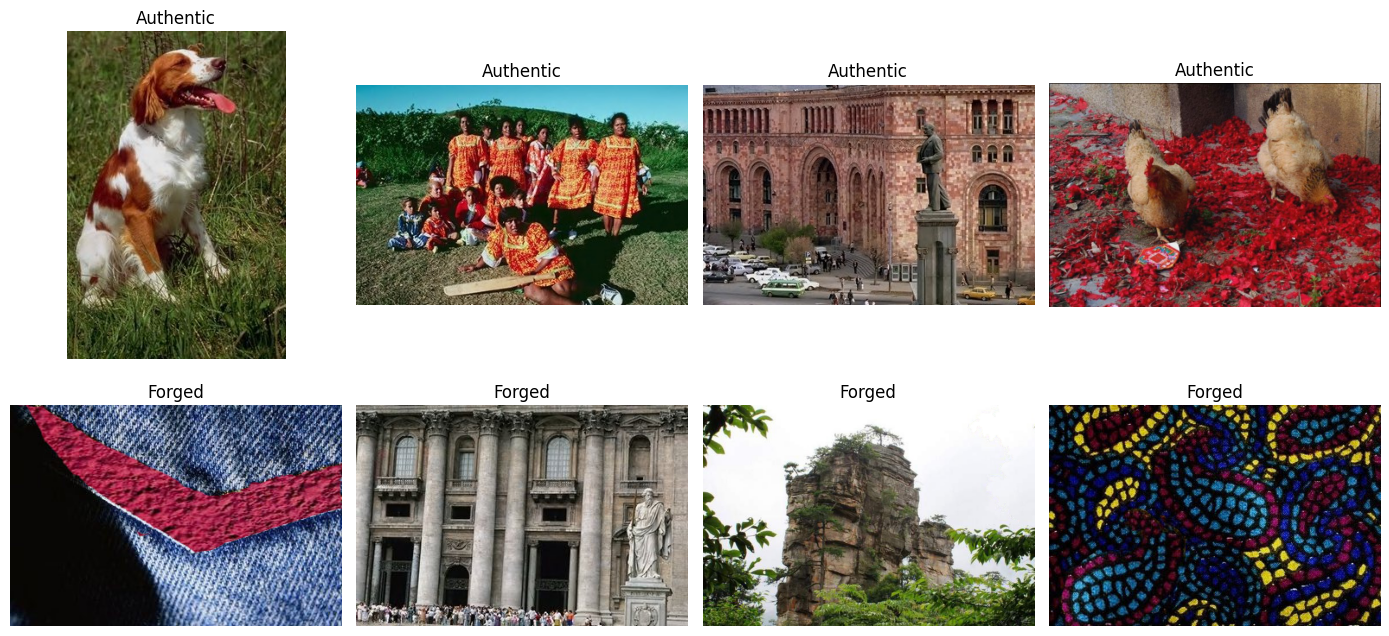

In [36]:
# ============================================================
# PHASE 4A.5 - VISUAL DATA CHECK
# ============================================================

import cv2

random.seed(42)

auth_samples = random.sample(
    authentic_files,
    min(4, len(authentic_files))
)

forged_samples = random.sample(
    forged_files,
    min(4, len(forged_files))
)

plt.figure(figsize=(14, 7))

# Authentic images
for i, filename in enumerate(auth_samples):

    path = os.path.join(
        AUTHENTIC_PATH,
        filename
    )

    image = cv2.imread(path)

    if image is None:
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title("Authentic")
    plt.axis("off")

# Forged images
for i, filename in enumerate(forged_samples):

    path = os.path.join(
        FORGED_PATH,
        filename
    )

    image = cv2.imread(path)

    if image is None:
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(2, 4, i + 5)
    plt.imshow(image)
    plt.title("Forged")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# PHASE 4A.6 - CREATE BALANCED DATASET
# ============================================================

BALANCED_PATH = "/content/balanced_dataset"

BALANCED_AUTH = os.path.join(
    BALANCED_PATH,
    "authentic"
)

BALANCED_FORGED = os.path.join(
    BALANCED_PATH,
    "forged"
)

# Remove previous balanced dataset if it exists
if os.path.exists(BALANCED_PATH):
    shutil.rmtree(BALANCED_PATH)

os.makedirs(BALANCED_AUTH)
os.makedirs(BALANCED_FORGED)

# Number of images to use
BALANCED_COUNT = min(
    len(authentic_files),
    len(forged_files)
)

print("Images per class:", BALANCED_COUNT)

Images per class: 5125


In [38]:
# ============================================================
# PHASE 4A.7 - COPY AUTHENTIC IMAGES
# ============================================================

random.seed(42)

selected_authentic = random.sample(
    authentic_files,
    BALANCED_COUNT
)

for filename in selected_authentic:

    source = os.path.join(
        AUTHENTIC_PATH,
        filename
    )

    destination = os.path.join(
        BALANCED_AUTH,
        filename
    )

    shutil.copy2(
        source,
        destination
    )

print(
    "Authentic images copied:",
    len(os.listdir(BALANCED_AUTH))
)

Authentic images copied: 5125


In [39]:
# ============================================================
# PHASE 4A.8 - COPY FORGED IMAGES
# ============================================================

random.seed(42)

selected_forged = random.sample(
    forged_files,
    BALANCED_COUNT
)

for filename in selected_forged:

    source = os.path.join(
        FORGED_PATH,
        filename
    )

    destination = os.path.join(
        BALANCED_FORGED,
        filename
    )

    shutil.copy2(
        source,
        destination
    )

print(
    "Forged images copied:",
    len(os.listdir(BALANCED_FORGED))
)

Forged images copied: 5125


In [40]:
# ============================================================
# PHASE 4A.9 - VERIFY BALANCED DATASET
# ============================================================

print("================================")
print("BALANCED DATASET")
print("================================")

print(
    "Authentic:",
    len(os.listdir(BALANCED_AUTH))
)

print(
    "Forged:",
    len(os.listdir(BALANCED_FORGED)
)

)

BALANCED DATASET
Authentic: 5125
Forged: 5125


In [41]:
# ============================================================
# PHASE 4A.10 - CLEAN DATA GENERATORS
# ============================================================

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.20

# Very light augmentation
train_datagen = ImageDataGenerator(
    rotation_range=5,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,

    validation_split=VALIDATION_SPLIT
)

# No augmentation for validation
validation_datagen = ImageDataGenerator(
    validation_split=VALIDATION_SPLIT
)

train_generator = train_datagen.flow_from_directory(
    BALANCED_PATH,

    target_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="binary",

    subset="training",

    shuffle=True,

    seed=42
)

validation_generator = validation_datagen.flow_from_directory(
    BALANCED_PATH,

    target_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="binary",

    subset="validation",

    shuffle=False,

    seed=42
)

print("\n================================")
print("GENERATOR CHECK")
print("================================")

print(
    "Training images:",
    train_generator.samples
)

print(
    "Validation images:",
    validation_generator.samples
)

print(
    "Classes:",
    train_generator.class_indices
)

Found 8199 images belonging to 2 classes.
Found 2048 images belonging to 2 classes.

GENERATOR CHECK
Training images: 8199
Validation images: 2048
Classes: {'authentic': 0, 'forged': 1}


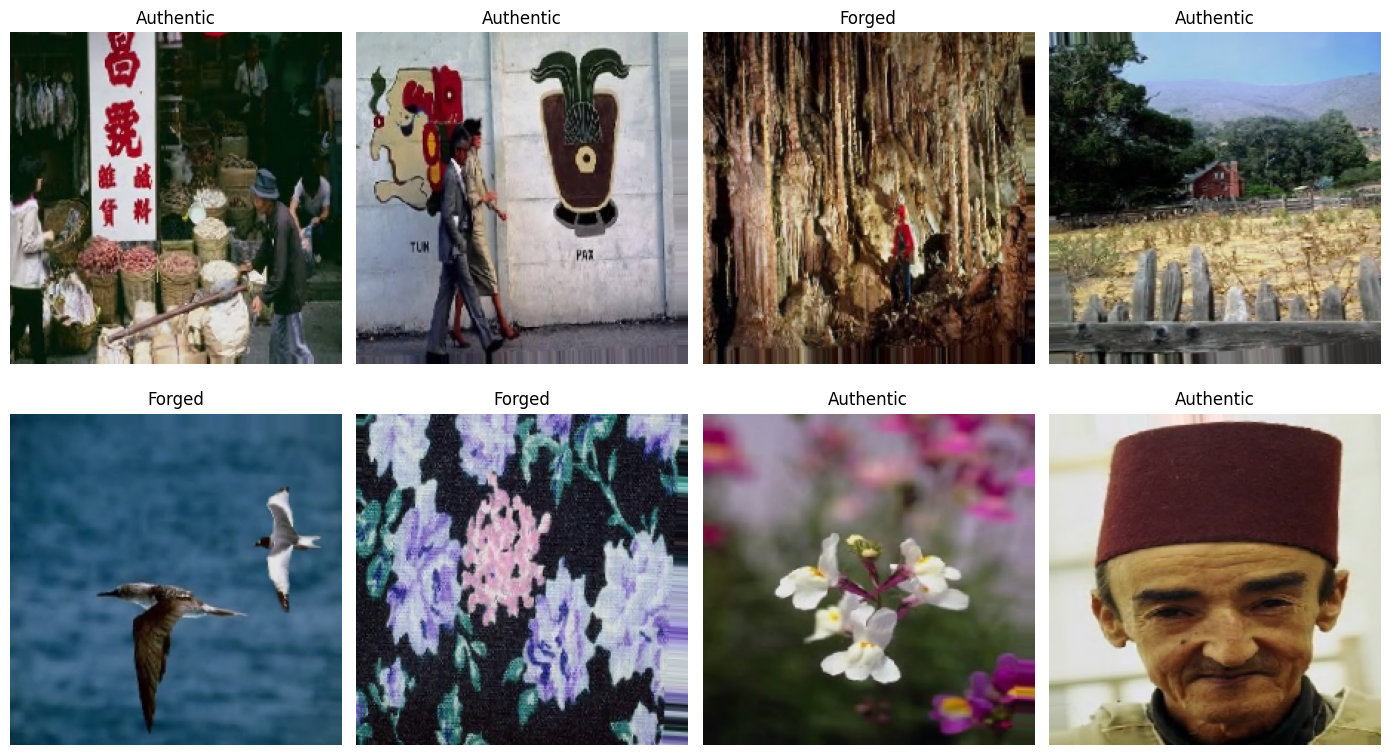

In [42]:
# ============================================================
# PHASE 4A.11 - GENERATOR VISUAL CHECK
# ============================================================

images, labels = next(train_generator)

plt.figure(figsize=(14, 8))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    plt.imshow(
        images[i].astype("uint8")
    )

    if labels[i] == 0:
        label = "Authentic"
    else:
        label = "Forged"

    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# PHASE 4A.12 - FRESH EFFICIENTNETB0
# ============================================================

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze initially
base_model.trainable = False

print("EfficientNetB0 loaded.")
print("Base model frozen.")

EfficientNetB0 loaded.
Base model frozen.


In [44]:
# ============================================================
# PHASE 4A.13 - CLASSIFICATION MODEL
# ============================================================

inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

# IMPORTANT:
# training=False keeps BatchNormalization layers
# in inference mode during transfer learning/fine-tuning.
x = base_model(
    inputs,
    training=False
)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(
    0.30
)(x)

x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(
    0.30
)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = tf.keras.Model(
    inputs,
    outputs
)

print("Model created.")

Model created.


In [45]:
# ============================================================
# PHASE 4A.14 - COMPILE
# ============================================================

model.compile(
    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print("Model compiled.")

Model compiled.


In [46]:
# ============================================================
# PHASE 4A.15 - MODEL SUMMARY
# ============================================================

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [47]:
# ============================================================
# PHASE 4A.16 - CALLBACKS
# ============================================================

checkpoint_stage1 = ModelCheckpoint(
    "/content/clean_stage1_best.keras",

    monitor="val_accuracy",

    save_best_only=True,

    mode="max",

    verbose=1
)

reduce_lr_stage1 = ReduceLROnPlateau(
    monitor="val_loss",

    factor=0.5,

    patience=2,

    min_lr=1e-7,

    verbose=1
)

print("Callbacks ready.")

Callbacks ready.


In [48]:
# ============================================================
# PHASE 4A.17 - STAGE 1 TRAINING
# ============================================================

STAGE1_EPOCHS = 15

print("======================================")
print("STAGE 1 TRAINING")
print("======================================")

history_stage1 = model.fit(

    train_generator,

    validation_data=validation_generator,

    epochs=STAGE1_EPOCHS,

    callbacks=[
        checkpoint_stage1,
        reduce_lr_stage1
    ],

    verbose=1
)

print("\nStage 1 training completed.")

STAGE 1 TRAINING
Epoch 1/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step - accuracy: 0.5282 - loss: 0.7204
Epoch 1: val_accuracy improved from None to 0.51172, saving model to /content/clean_stage1_best.keras

Epoch 1: finished saving model to /content/clean_stage1_best.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 173s 556ms/step - accuracy: 0.5602 - loss: 0.6917 - val_accuracy: 0.5117 - val_loss: 0.7201 - learning_rate: 1.0000e-04
Epoch 2/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - accuracy: 0.6340 - loss: 0.6362
Epoch 2: val_accuracy improved from 0.51172 to 0.52100, saving model to /content/clean_stage1_best.keras

Epoch 2: finished saving model to /content/clean_stage1_best.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 118s 460ms/step - accuracy: 0.6369 - loss: 0.6318 - val_accuracy: 0.5210 - val_loss: 0.7286 - learning_rate: 1.0000e-04
Epoch 3/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.6802 - loss: 0.6040
Epoch 3: val_accuracy did not improve from 0.52100

Epoch 3: ReduceLROnPlateau

In [49]:
# ============================================================
# PHASE 4A.18 - LOAD BEST MODEL
# ============================================================

best_stage1_model = tf.keras.models.load_model(
    "/content/clean_stage1_best.keras"
)

print("Best Stage 1 model loaded.")

Best Stage 1 model loaded.


In [50]:
# ============================================================
# PHASE 4A.19 - STAGE 1 EVALUATION
# ============================================================

validation_generator.reset()

stage1_result = best_stage1_model.evaluate(
    validation_generator,
    verbose=1
)

stage1_loss = stage1_result[0]
stage1_accuracy = stage1_result[1]

print("\n======================================")
print("STAGE 1 RESULT")
print("======================================")

print(
    "Validation Loss:",
    round(stage1_loss, 4)
)

print(
    "Validation Accuracy:",
    round(stage1_accuracy * 100, 2),
    "%"
)

64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 102ms/step - accuracy: 0.5239 - loss: 0.7717

STAGE 1 RESULT
Validation Loss: 0.7717
Validation Accuracy: 52.39 %


In [51]:
# ============================================================
# PHASE 4A.20 - FINE-TUNING SETUP
# ============================================================

model = best_stage1_model

# Find the EfficientNet base model
base_model = None

for layer in model.layers:

    if isinstance(
        layer,
        tf.keras.Model
    ) and "efficientnet" in layer.name.lower():

        base_model = layer
        break

if base_model is None:

    print("EfficientNet base model not found.")

    print("\nModel layers:")

    for layer in model.layers:
        print(
            layer.name,
            type(layer)
        )

    raise ValueError(
        "EfficientNet base model could not be found."
    )

print(
    "EfficientNet base model:",
    base_model.name
)

EfficientNet base model: efficientnetb0


In [52]:
# ============================================================
# PHASE 4A.21 - UNFREEZE UPPER LAYERS
# ============================================================

base_model.trainable = True

# Freeze most layers
for layer in base_model.layers[:-40]:

    layer.trainable = False

# Unfreeze final 40 layers,
# except BatchNormalization layers.
for layer in base_model.layers[-40:]:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):

        layer.trainable = False

    else:

        layer.trainable = True

trainable_layers = 0
frozen_layers = 0

for layer in base_model.layers:

    if layer.trainable:
        trainable_layers += 1
    else:
        frozen_layers += 1

print("================================")
print("FINE-TUNING SETUP")
print("================================")

print(
    "Trainable EfficientNet layers:",
    trainable_layers
)

print(
    "Frozen EfficientNet layers:",
    frozen_layers
)

FINE-TUNING SETUP
Trainable EfficientNet layers: 32
Frozen EfficientNet layers: 206


In [53]:
# ============================================================
# PHASE 4A.22 - RECOMPILE FOR FINE-TUNING
# ============================================================

model.compile(
    optimizer=Adam(
        learning_rate=1e-5
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print(
    "Fine-tuning learning rate: 0.00001"
)

Fine-tuning learning rate: 0.00001


In [54]:
# ============================================================
# PHASE 4A.23 - FINE-TUNING CALLBACKS
# ============================================================

checkpoint_stage2 = ModelCheckpoint(
    "/content/clean_final_forgery_model.keras",

    monitor="val_accuracy",

    save_best_only=True,

    mode="max",

    verbose=1
)

reduce_lr_stage2 = ReduceLROnPlateau(
    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-8,

    verbose=1
)

print("Fine-tuning callbacks ready.")

Fine-tuning callbacks ready.


In [55]:
# ============================================================
# PHASE 4A.24 - FINE-TUNING
# ============================================================

STAGE2_EPOCHS = 15

print("======================================")
print("STAGE 2 - FINE-TUNING")
print("======================================")

history_stage2 = model.fit(

    train_generator,

    validation_data=validation_generator,

    epochs=STAGE2_EPOCHS,

    callbacks=[
        checkpoint_stage2,
        reduce_lr_stage2
    ],

    verbose=1
)

print("\nFine-tuning completed.")

STAGE 2 - FINE-TUNING
Epoch 1/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step - accuracy: 0.6944 - loss: 0.5728
Epoch 1: val_accuracy improved from None to 0.50537, saving model to /content/clean_final_forgery_model.keras

Epoch 1: finished saving model to /content/clean_final_forgery_model.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 160s 513ms/step - accuracy: 0.6947 - loss: 0.5717 - val_accuracy: 0.5054 - val_loss: 0.8285 - learning_rate: 1.0000e-05
Epoch 2/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 416ms/step - accuracy: 0.7015 - loss: 0.5530
Epoch 2: val_accuracy did not improve from 0.50537
257/257 ━━━━━━━━━━━━━━━━━━━━ 113s 439ms/step - accuracy: 0.7079 - loss: 0.5527 - val_accuracy: 0.4980 - val_loss: 0.8822 - learning_rate: 1.0000e-05
Epoch 3/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.7277 - loss: 0.5334
Epoch 3: val_accuracy did not improve from 0.50537
257/257 ━━━━━━━━━━━━━━━━━━━━ 111s 434ms/step - accuracy: 0.7151 - loss: 0.5451 - val_accuracy: 0.4961 - val_loss: 0.9289 - learn

In [56]:
# ============================================================
# PHASE 4A.25 - LOAD FINAL MODEL
# ============================================================

final_model = tf.keras.models.load_model(
    "/content/clean_final_forgery_model.keras"
)

print("Final best model loaded.")

Final best model loaded.


In [57]:
# ============================================================
# PHASE 4A.26 - FINAL EVALUATION
# ============================================================

validation_generator.reset()

final_result = final_model.evaluate(
    validation_generator,
    verbose=1
)

final_loss = final_result[0]
final_accuracy = final_result[1]

print("\n======================================")
print("FINAL CLEAN TRAINING RESULT")
print("======================================")

print(
    "Validation Loss:",
    round(final_loss, 4)
)

print(
    "Validation Accuracy:",
    round(final_accuracy * 100, 2),
    "%"
)

64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 97ms/step - accuracy: 0.5054 - loss: 0.8285

FINAL CLEAN TRAINING RESULT
Validation Loss: 0.8285
Validation Accuracy: 50.54 %


In [58]:
# ============================================================
# PHASE 4A.27 - COMPARE RESULTS
# ============================================================

best_stage1_accuracy = max(
    history_stage1.history["val_accuracy"]
)

best_stage2_accuracy = max(
    history_stage2.history["val_accuracy"]
)

print("\n======================================")
print("RESULT COMPARISON")
print("======================================")

print(
    "Stage 1 best:",
    round(best_stage1_accuracy * 100, 2),
    "%"
)

print(
    "Stage 2 best:",
    round(best_stage2_accuracy * 100, 2),
    "%"
)

print(
    "Final evaluation:",
    round(final_accuracy * 100, 2),
    "%"
)

print(
    "Previous model:",
    "45.56%"
)

print("======================================")


RESULT COMPARISON
Stage 1 best: 52.39 %
Stage 2 best: 50.54 %
Final evaluation: 50.54 %
Previous model: 45.56%


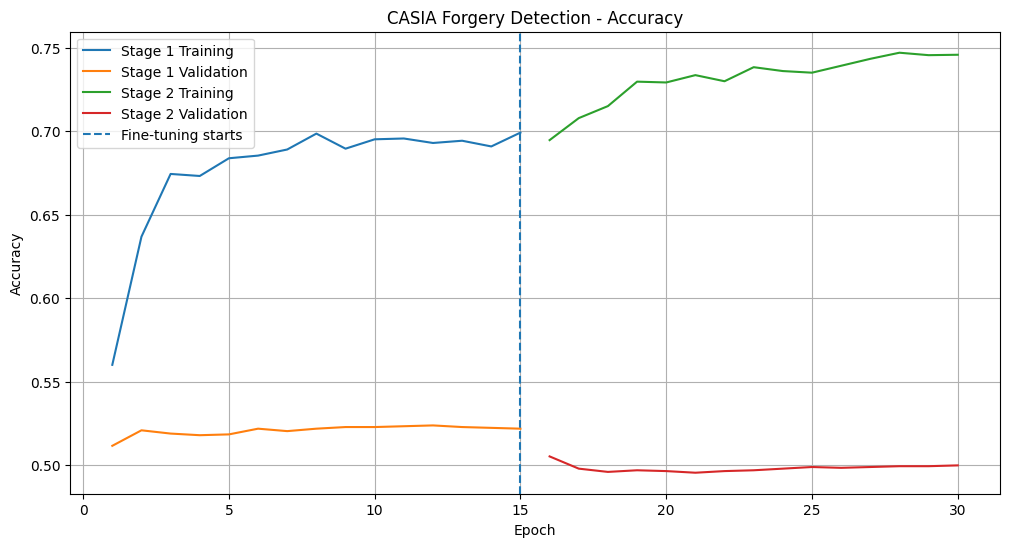

In [59]:
# ============================================================
# PHASE 4A.28 - ACCURACY GRAPH
# ============================================================

stage1_train_acc = history_stage1.history["accuracy"]
stage1_val_acc = history_stage1.history["val_accuracy"]

stage2_train_acc = history_stage2.history["accuracy"]
stage2_val_acc = history_stage2.history["val_accuracy"]

stage1_length = len(stage1_train_acc)

plt.figure(figsize=(12, 6))

plt.plot(
    range(1, stage1_length + 1),
    stage1_train_acc,
    label="Stage 1 Training"
)

plt.plot(
    range(1, stage1_length + 1),
    stage1_val_acc,
    label="Stage 1 Validation"
)

plt.plot(
    range(
        stage1_length + 1,
        stage1_length + len(stage2_train_acc) + 1
    ),
    stage2_train_acc,
    label="Stage 2 Training"
)

plt.plot(
    range(
        stage1_length + 1,
        stage1_length + len(stage2_val_acc) + 1
    ),
    stage2_val_acc,
    label="Stage 2 Validation"
)

plt.axvline(
    stage1_length,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title(
    "CASIA Forgery Detection - Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

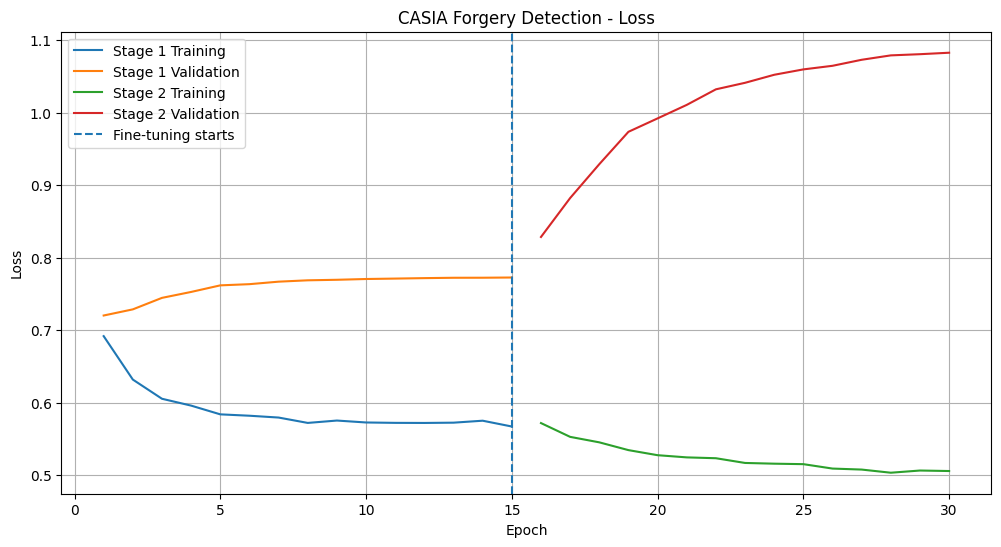

In [60]:
# ============================================================
# PHASE 4A.29 - LOSS GRAPH
# ============================================================

stage1_train_loss = history_stage1.history["loss"]
stage1_val_loss = history_stage1.history["val_loss"]

stage2_train_loss = history_stage2.history["loss"]
stage2_val_loss = history_stage2.history["val_loss"]

plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(stage1_train_loss) + 1),
    stage1_train_loss,
    label="Stage 1 Training"
)

plt.plot(
    range(1, len(stage1_val_loss) + 1),
    stage1_val_loss,
    label="Stage 1 Validation"
)

plt.plot(
    range(
        len(stage1_train_loss) + 1,
        len(stage1_train_loss)
        + len(stage2_train_loss) + 1
    ),
    stage2_train_loss,
    label="Stage 2 Training"
)

plt.plot(
    range(
        len(stage1_train_loss) + 1,
        len(stage1_train_loss)
        + len(stage2_val_loss) + 1
    ),
    stage2_val_loss,
    label="Stage 2 Validation"
)

plt.axvline(
    len(stage1_train_loss),
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title(
    "CASIA Forgery Detection - Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

In [61]:
# ============================================================
# PHASE 4A.30 - SAVE MODEL + HISTORY
# ============================================================

import json

# Save Stage 1 history
with open(
    "/content/clean_stage1_history.json",
    "w"
) as f:

    json.dump(
        history_stage1.history,
        f
    )

# Save Stage 2 history
with open(
    "/content/clean_stage2_history.json",
    "w"
) as f:

    json.dump(
        history_stage2.history,
        f
    )

print("================================")
print("FILES SAVED")
print("================================")

print(
    "/content/clean_stage1_best.keras"
)

print(
    "/content/clean_final_forgery_model.keras"
)

print(
    "/content/clean_stage1_history.json"
)

print(
    "/content/clean_stage2_history.json"
)

FILES SAVED
/content/clean_stage1_best.keras
/content/clean_final_forgery_model.keras
/content/clean_stage1_history.json
/content/clean_stage2_history.json


In [62]:
# ============================================================
# PHASE 4A.31 - FINAL SUMMARY
# ============================================================

print("""
==================================================
       CASIA FORGERY DETECTOR
       CLEAN TRAINING COMPLETE
==================================================
""")

print(
    "Balanced authentic images:",
    len(os.listdir(BALANCED_AUTH))
)

print(
    "Balanced forged images:",
    len(os.listdir(BALANCED_FORGED))
)

print(
    "\nStage 1 best validation accuracy:",
    round(
        best_stage1_accuracy * 100,
        2
    ),
    "%"
)

print(
    "Stage 2 best validation accuracy:",
    round(
        best_stage2_accuracy * 100,
        2
    ),
    "%"
)

print(
    "Final validation accuracy:",
    round(
        final_accuracy * 100,
        2
    ),
    "%"
)



       CASIA FORGERY DETECTOR
       CLEAN TRAINING COMPLETE

Balanced authentic images: 5125
Balanced forged images: 5125

Stage 1 best validation accuracy: 52.39 %
Stage 2 best validation accuracy: 50.54 %
Final validation accuracy: 50.54 %


Model loaded successfully.
EfficientNet base model:
efficientnetb0

Grad-CAM layer:
top_conv
Output shape: (None, 7, 7, 1280)

Classifier layers:
global_average_pooling2d_1 GlobalAveragePooling2D
dropout_1 Dropout
dense_1 Dense
dropout_2 Dropout
dense_2 Dense

Gradient feature model created.


ANALYZING
/content/balanced_dataset/forged/Tp_D_NRN_S_N_art00013_art00082_11816.jpg


RESULT
Prediction: AUTHENTIC
Forgery Score: 20.64%
Heatmap threshold: 0.55
Suspicious bounding box: (167, 0, 50, 33)
Suspicious area: 1332 pixels


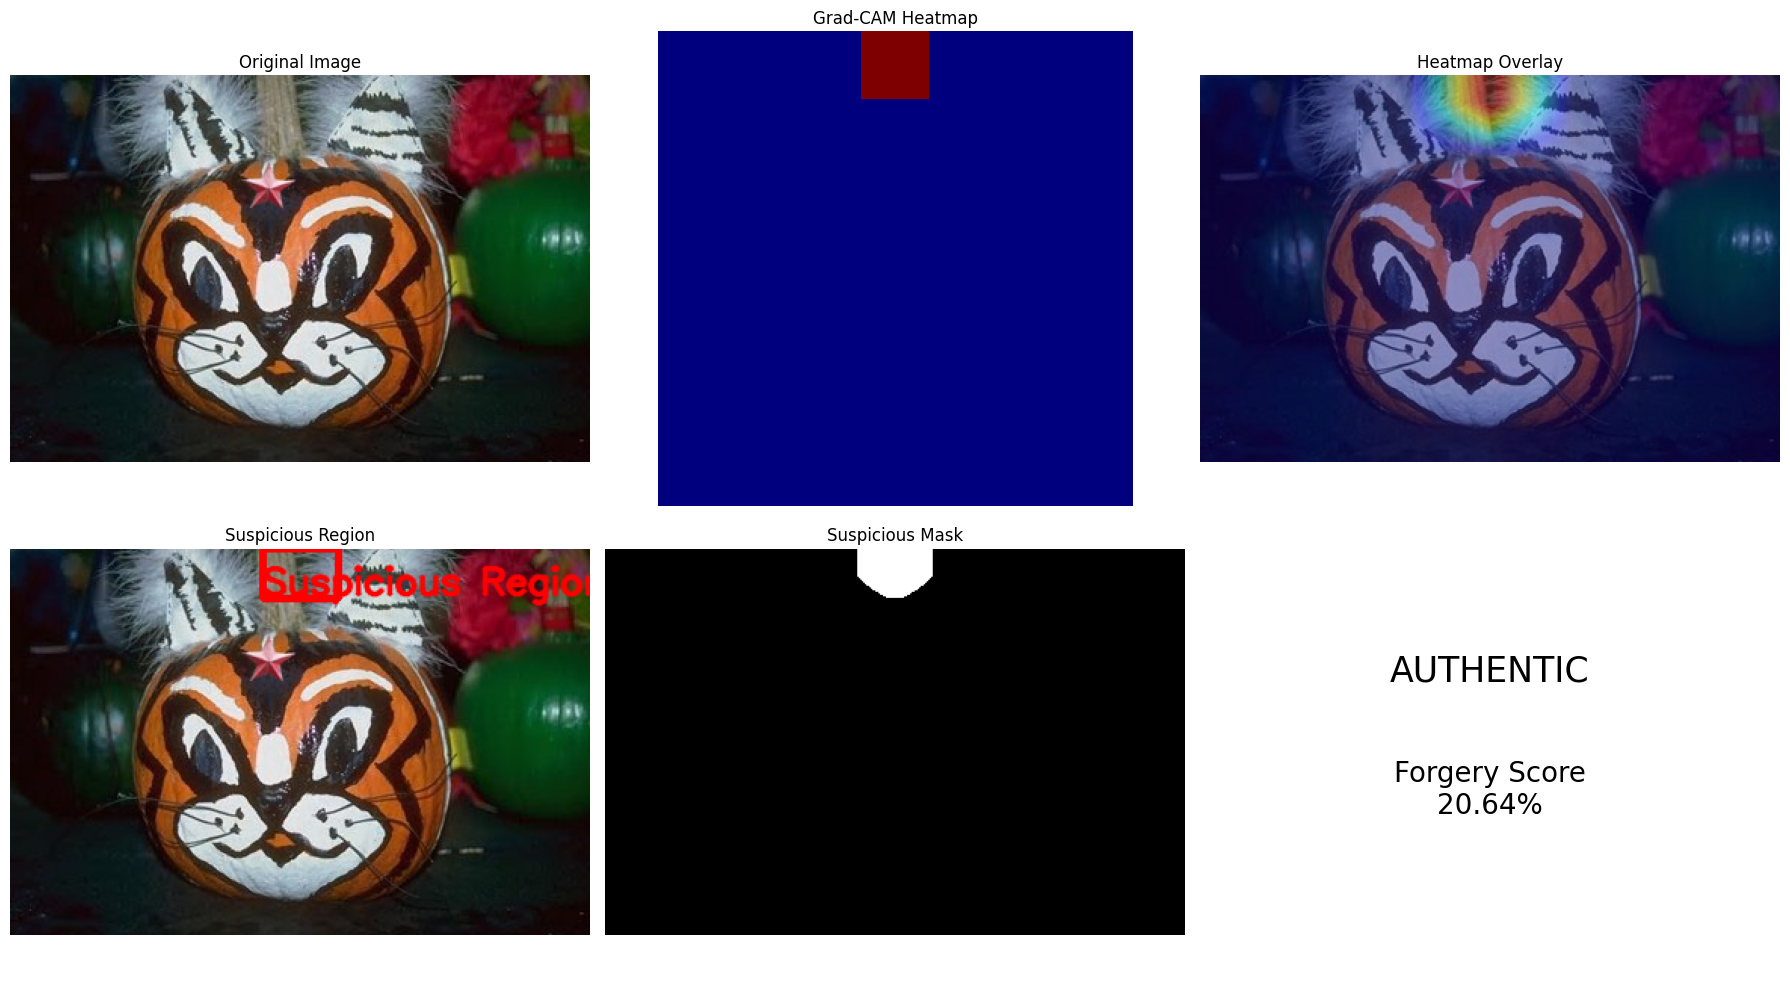



PHASE 12 COMPLETED SUCCESSFULLY
Results folder:
/content/phase12_results

Files:
original.png
heatmap.png
overlay.png
suspicious_region.png
mask.png


In [63]:
# ============================================================
# PHASE 12 - FINAL CORRECTED GRAD-CAM
# ============================================================

import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD MODEL
# ============================================================

MODEL_PATH = "/content/clean_final_forgery_model.keras"

model = tf.keras.models.load_model(
    MODEL_PATH
)

print("Model loaded successfully.")


# ============================================================
# 2. FIND EFFICIENTNET BASE MODEL
# ============================================================

base_model = None

for layer in model.layers:

    if isinstance(layer, tf.keras.Model):

        if "efficientnet" in layer.name.lower():

            base_model = layer
            break


if base_model is None:

    raise ValueError(
        "EfficientNet base model was not found."
    )


print("EfficientNet base model:")
print(base_model.name)


# ============================================================
# 3. FIND LAST CONVOLUTIONAL LAYER
# ============================================================

last_conv_layer = None

for layer in reversed(base_model.layers):

    if isinstance(
        layer,
        (
            tf.keras.layers.Conv2D,
            tf.keras.layers.DepthwiseConv2D
        )
    ):

        last_conv_layer = layer
        break


if last_conv_layer is None:

    # fallback: any layer producing 4D output
    for layer in reversed(base_model.layers):

        try:

            if len(layer.output.shape) == 4:

                last_conv_layer = layer
                break

        except Exception:

            pass


if last_conv_layer is None:

    raise ValueError(
        "Could not find convolutional layer."
    )


print("\nGrad-CAM layer:")
print(last_conv_layer.name)

print(
    "Output shape:",
    last_conv_layer.output.shape
)


# ============================================================
# 4. IDENTIFY CLASSIFIER LAYERS
# ============================================================
#
# The outer model looks approximately like:
#
# Input
#   ↓
# EfficientNet
#   ↓
# GlobalAveragePooling
#   ↓
# Dropout
#   ↓
# Dense
#   ↓
# Dropout
#   ↓
# Dense(sigmoid)
#
# We reuse the classifier layers after EfficientNet.

base_index = None

for i, layer in enumerate(model.layers):

    if layer is base_model:

        base_index = i
        break


if base_index is None:

    raise ValueError(
        "Could not locate EfficientNet inside model."
    )


classifier_layers = model.layers[
    base_index + 1:
]


print("\nClassifier layers:")

for layer in classifier_layers:

    print(
        layer.name,
        type(layer).__name__
    )


# ============================================================
# 5. BUILD GRADIENT MODEL
# ============================================================
#
# IMPORTANT:
#
# We construct everything from the SAME EfficientNet graph.
#
# This fixes:
#
# KeyError
# gradients are None
# input structure mismatch
#
# ============================================================

grad_model = tf.keras.Model(

    inputs=base_model.input,

    outputs=[
        last_conv_layer.output,
        base_model.output
    ]

)


print("\nGradient feature model created.")


# ============================================================
# 6. IMAGE PREPARATION
# ============================================================

IMAGE_SIZE = (224, 224)


def prepare_image(image_path):

    image = cv2.imread(
        image_path
    )

    if image is None:

        raise ValueError(
            "Could not read image:\n"
            + image_path
        )

    # BGR → RGB
    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Resize
    resized = cv2.resize(
        image_rgb,
        IMAGE_SIZE
    )

    # EfficientNet model accepts pixel values.
    # Do NOT add 1/255 here because the Keras
    # EfficientNet implementation handles its
    # preprocessing internally.

    tensor = resized.astype(
        np.float32
    )

    # Add batch dimension
    tensor = np.expand_dims(
        tensor,
        axis=0
    )

    return (
        image_rgb,
        tensor
    )


# ============================================================
# 7. GRAD-CAM FUNCTION
# ============================================================

def generate_gradcam(
    image_tensor
):

    # --------------------------------------------------------
    # Gradient calculation
    # --------------------------------------------------------

    with tf.GradientTape() as tape:

        # Get:
        #
        # 1. last convolutional feature maps
        # 2. final EfficientNet feature representation

        conv_outputs, base_outputs = grad_model(
            image_tensor,
            training=False
        )

        # IMPORTANT:
        # Watch the convolution output directly.
        tape.watch(
            conv_outputs
        )

        # ----------------------------------------------------
        # Run the classifier
        # ----------------------------------------------------

        x = base_outputs

        for layer in classifier_layers:

            x = layer(
                x,
                training=False
            )

        predictions = x

        # Forged probability
        forged_score = predictions[:, 0]


    # --------------------------------------------------------
    # Calculate gradients
    # --------------------------------------------------------

    gradients = tape.gradient(
        forged_score,
        conv_outputs
    )


    # Safety check
    if gradients is None:

        raise ValueError(
            "Gradients are still None. "
            "The selected layer is not connected "
            "to the classifier."
        )


    # --------------------------------------------------------
    # Global average pooling of gradients
    # --------------------------------------------------------

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )


    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    pooled_gradients = pooled_gradients[0]


    # --------------------------------------------------------
    # Weight feature maps
    # --------------------------------------------------------

    weighted_features = (
        conv_outputs *
        pooled_gradients
    )


    # Sum across channels
    heatmap = tf.reduce_sum(
        weighted_features,
        axis=-1
    )


    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )


    # Normalize
    max_heat = tf.reduce_max(
        heatmap
    )

    heatmap = tf.where(
        max_heat > 0,
        heatmap / max_heat,
        heatmap
    )


    return (
        heatmap.numpy(),
        float(
            forged_score.numpy()[0]
        )
    )


# ============================================================
# 8. CREATE HEATMAP OVERLAY
# ============================================================

def create_overlay(
    original_image,
    heatmap
):

    # Convert heatmap to uint8
    heatmap_uint8 = np.uint8(
        heatmap * 255
    )

    # Resize
    heatmap_uint8 = cv2.resize(
        heatmap_uint8,
        (
            original_image.shape[1],
            original_image.shape[0]
        )
    )

    # Color map
    colored = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # RGB → BGR
    original_bgr = cv2.cvtColor(
        original_image,
        cv2.COLOR_RGB2BGR
    )

    # Overlay
    overlay = cv2.addWeighted(
        original_bgr,
        0.60,
        colored,
        0.40,
        0
    )

    # BGR → RGB
    overlay = cv2.cvtColor(
        overlay,
        cv2.COLOR_BGR2RGB
    )

    return (
        heatmap_uint8,
        overlay
    )


# ============================================================
# 9. FIND SUSPICIOUS REGION
# ============================================================

def find_suspicious_region(
    original_image,
    heatmap,
    threshold=0.55
):

    # Normalize
    if heatmap.max() > 0:

        heatmap_normalized = (
            heatmap /
            heatmap.max()
        )

    else:

        heatmap_normalized = heatmap


    # Resize
    heatmap_resized = cv2.resize(
        heatmap_normalized,
        (
            original_image.shape[1],
            original_image.shape[0]
        )
    )


    # Threshold
    mask = (
        heatmap_resized >= threshold
    ).astype(
        np.uint8
    ) * 255


    # Remove noise
    kernel = np.ones(
        (7, 7),
        np.uint8
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )


    # Find contours
    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )


    # Find largest region
    best_contour = None
    best_area = 0


    for contour in contours:

        area = cv2.contourArea(
            contour
        )

        if area > best_area:

            best_area = area

            best_contour = contour


    # Create output
    boxed = original_image.copy()


    if best_contour is not None:

        x, y, w, h = cv2.boundingRect(
            best_contour
        )

        cv2.rectangle(
            boxed,

            (x, y),

            (x + w, y + h),

            (255, 0, 0),

            4
        )

        cv2.putText(
            boxed,

            "Suspicious Region",

            (
                x,
                max(
                    30,
                    y - 10
                )
            ),

            cv2.FONT_HERSHEY_SIMPLEX,

            0.8,

            (255, 0, 0),

            2,

            cv2.LINE_AA
        )

        bounding_box = (
            x,
            y,
            w,
            h
        )

    else:

        bounding_box = None


    return (
        mask,
        boxed,
        bounding_box,
        best_area
    )


# ============================================================
# 10. COMPLETE IMAGE ANALYZER
# ============================================================

def analyze_forgery(
    image_path,
    threshold=0.55
):

    print("\n")
    print("=" * 60)
    print("ANALYZING")
    print("=" * 60)

    print(image_path)


    # Load image
    original_image, image_tensor = (
        prepare_image(
            image_path
        )
    )


    # Generate Grad-CAM
    heatmap, score = generate_gradcam(
        image_tensor
    )


    # Classification
    if score >= 0.50:

        label = "FORGED"

    else:

        label = "AUTHENTIC"


    # Overlay
    heatmap_image, overlay = (
        create_overlay(
            original_image,
            heatmap
        )
    )


    # Suspicious region
    mask, boxed_image, bounding_box, area = (
        find_suspicious_region(
            original_image,
            heatmap,
            threshold
        )
    )


    # Print result
    print("\n")
    print("=" * 60)
    print("RESULT")
    print("=" * 60)

    print(
        "Prediction:",
        label
    )

    print(
        f"Forgery Score: {score * 100:.2f}%"
    )

    print(
        f"Heatmap threshold: {threshold}"
    )


    if bounding_box is not None:

        print(
            "Suspicious bounding box:",
            bounding_box
        )

        print(
            f"Suspicious area: {area:.0f} pixels"
        )

    else:

        print(
            "Suspicious region: Not detected"
        )


    return {

        "original":
            original_image,

        "heatmap":
            heatmap,

        "heatmap_image":
            heatmap_image,

        "overlay":
            overlay,

        "mask":
            mask,

        "boxed_image":
            boxed_image,

        "score":
            score,

        "label":
            label,

        "bounding_box":
            bounding_box,

        "area":
            area
    }


# ============================================================
# 11. TEST YOUR FORGED IMAGE
# ============================================================

test_forged_image = (
    "/content/balanced_dataset/forged/"
    "Tp_D_NRN_S_N_art00013_art00082_11816.jpg"
)


result_forged = analyze_forgery(
    test_forged_image
)


# ============================================================
# 12. DISPLAY RESULTS
# ============================================================

plt.figure(
    figsize=(18, 10)
)


# Original
plt.subplot(
    2,
    3,
    1
)

plt.imshow(
    result_forged["original"]
)

plt.title(
    "Original Image"
)

plt.axis("off")


# Heatmap
plt.subplot(
    2,
    3,
    2
)

plt.imshow(
    result_forged["heatmap"],
    cmap="jet"
)

plt.title(
    "Grad-CAM Heatmap"
)

plt.axis("off")


# Overlay
plt.subplot(
    2,
    3,
    3
)

plt.imshow(
    result_forged["overlay"]
)

plt.title(
    "Heatmap Overlay"
)

plt.axis("off")


# Suspicious region
plt.subplot(
    2,
    3,
    4
)

plt.imshow(
    result_forged["boxed_image"]
)

plt.title(
    "Suspicious Region"
)

plt.axis("off")


# Mask
plt.subplot(
    2,
    3,
    5
)

plt.imshow(
    result_forged["mask"],
    cmap="gray"
)

plt.title(
    "Suspicious Mask"
)

plt.axis("off")


# Score
plt.subplot(
    2,
    3,
    6
)

plt.axis("off")

plt.text(
    0.5,
    0.65,
    result_forged["label"],
    ha="center",
    va="center",
    fontsize=25
)

plt.text(
    0.5,
    0.40,
    f"Forgery Score\n"
    f"{result_forged['score'] * 100:.2f}%",
    ha="center",
    va="center",
    fontsize=20
)


plt.tight_layout()

plt.show()


# ============================================================
# 13. SAVE RESULTS
# ============================================================

RESULT_DIR = (
    "/content/phase12_results"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)


# Original
cv2.imwrite(
    f"{RESULT_DIR}/original.png",

    cv2.cvtColor(
        result_forged["original"],
        cv2.COLOR_RGB2BGR
    )
)


# Heatmap
cv2.imwrite(
    f"{RESULT_DIR}/heatmap.png",

    result_forged["heatmap_image"]
)


# Overlay
cv2.imwrite(
    f"{RESULT_DIR}/overlay.png",

    cv2.cvtColor(
        result_forged["overlay"],
        cv2.COLOR_RGB2BGR
    )
)


# Suspicious region
cv2.imwrite(
    f"{RESULT_DIR}/suspicious_region.png",

    cv2.cvtColor(
        result_forged["boxed_image"],
        cv2.COLOR_RGB2BGR
    )
)


# Mask
cv2.imwrite(
    f"{RESULT_DIR}/mask.png",

    result_forged["mask"]
)


print("\n")
print("=" * 60)
print("PHASE 12 COMPLETED SUCCESSFULLY")
print("=" * 60)

print(
    "Results folder:"
)

print(
    RESULT_DIR
)

print("\nFiles:")

print("original.png")
print("heatmap.png")
print("overlay.png")
print("suspicious_region.png")
print("mask.png")

Saving lake-mountains.jpg to lake-mountains.jpg
Selected image:
lake-mountains.jpg


ANALYZING
lake-mountains.jpg


RESULT
Prediction: FORGED
Forgery Score: 50.05%
Heatmap threshold: 0.55
Suspicious bounding box: (538, 669, 2552, 1312)
Suspicious area: 2416550 pixels

       AI DOCUMENT FORGERY ANALYZER
Image          : lake-mountains.jpg
Forgery Score  : 50.05%
Prediction     : FORGED
Suspicious Region: x=538, y=669, width=2552, height=1312


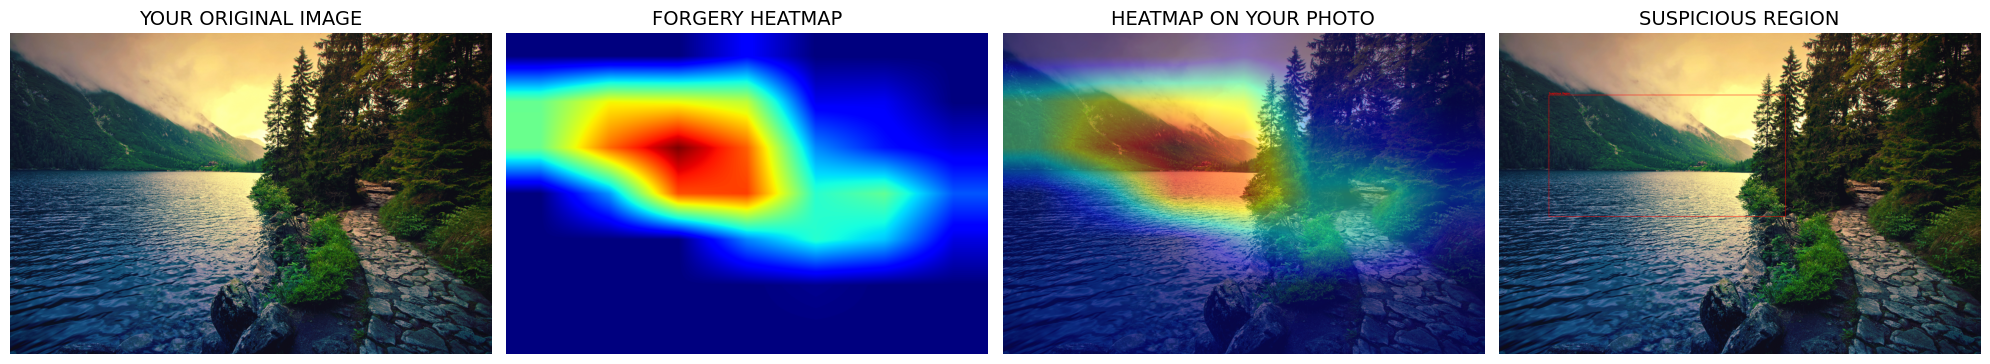

In [64]:
# ============================================================
# TEST YOUR OWN IMAGE FROM YOUR COMPUTER
# ============================================================

from google.colab import files
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Upload image from your computer
uploaded = files.upload()

# Get uploaded filename
image_path = list(uploaded.keys())[0]

print("Selected image:")
print(image_path)

# ============================================================
# ANALYZE YOUR IMAGE
# ============================================================

result_own = analyze_forgery(
    image_path,
    threshold=0.55
)

# ============================================================
# PRINT CLEAN RESULT
# ============================================================

score = result_own["score"] * 100

print("\n" + "=" * 60)
print("       AI DOCUMENT FORGERY ANALYZER")
print("=" * 60)

print(f"Image          : {image_path}")
print(f"Forgery Score  : {score:.2f}%")
print(f"Prediction     : {result_own['label']}")

if result_own["bounding_box"] is not None:

    x, y, w, h = result_own["bounding_box"]

    print(
        f"Suspicious Region: "
        f"x={x}, y={y}, width={w}, height={h}"
    )

else:

    print("Suspicious Region: Not clearly detected")

print("=" * 60)


# ============================================================
# CREATE PHOTO HEATMAP
# ============================================================

original = result_own["original"]
heatmap = result_own["heatmap"]

# Normalize heatmap
if heatmap.max() > 0:

    heatmap_normalized = (
        heatmap / heatmap.max()
    )

else:

    heatmap_normalized = heatmap


# Resize heatmap to ORIGINAL PHOTO SIZE
heatmap_full = cv2.resize(
    heatmap_normalized,
    (
        original.shape[1],
        original.shape[0]
    )
)


# Convert heatmap to color
heatmap_uint8 = np.uint8(
    heatmap_full * 255
)

colored_heatmap = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

colored_heatmap = cv2.cvtColor(
    colored_heatmap,
    cv2.COLOR_BGR2RGB
)


# ============================================================
# OVERLAY HEATMAP ON YOUR ACTUAL PHOTO
# ============================================================

photo_map = cv2.addWeighted(
    original,
    0.55,
    colored_heatmap,
    0.45,
    0
)


# ============================================================
# SHOW EVERYTHING
# ============================================================

plt.figure(figsize=(20, 6))


# 1. ORIGINAL
plt.subplot(1, 4, 1)

plt.imshow(
    original
)

plt.title(
    "YOUR ORIGINAL IMAGE",
    fontsize=14
)

plt.axis("off")


# 2. HEATMAP
plt.subplot(1, 4, 2)

plt.imshow(
    heatmap_full,
    cmap="jet"
)

plt.title(
    "FORGERY HEATMAP",
    fontsize=14
)

plt.axis("off")


# 3. PHOTO MAP
plt.subplot(1, 4, 3)

plt.imshow(
    photo_map
)

plt.title(
    "HEATMAP ON YOUR PHOTO",
    fontsize=14
)

plt.axis("off")


# 4. SUSPICIOUS REGION
plt.subplot(1, 4, 4)

plt.imshow(
    result_own["boxed_image"]
)

plt.title(
    "SUSPICIOUS REGION",
    fontsize=14
)

plt.axis("off")


plt.tight_layout()

plt.show()

Found 7188 files belonging to 2 classes.
MODEL EVALUATION
Accuracy  : 0.6575
Precision : 0.4435
Recall    : 0.7573
F1 Score  : 0.5594
ROC-AUC   : 0.7484


CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Authentic       0.86      0.62      0.72      5124
      Forged       0.44      0.76      0.56      2064

    accuracy                           0.66      7188
   macro avg       0.65      0.69      0.64      7188
weighted avg       0.74      0.66      0.67      7188



CONFUSION MATRIX
[[3163 1961]
 [ 501 1563]]


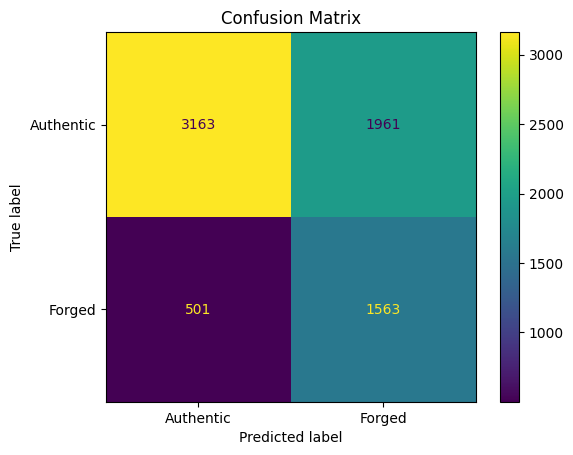

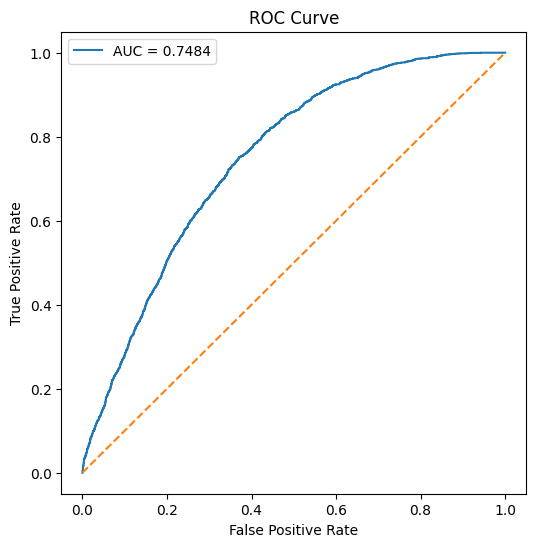

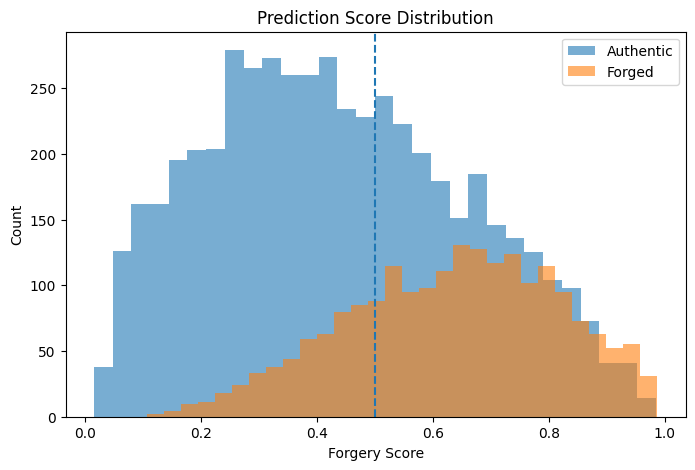

In [65]:
# ============================================================
# COMPLETE EVALUATION
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# LOAD TEST DATASET
# ------------------------------------------------------------

test_dataset = tf.keras.utils.image_dataset_from_directory(
    "/content/balanced_dataset",
    labels="inferred",
    label_mode="binary",
    image_size=(224,224),
    batch_size=32,
    shuffle=False
)

# ------------------------------------------------------------
# PREDICTIONS
# ------------------------------------------------------------

y_true = []
y_scores = []

for images, labels in test_dataset:

    preds = model.predict(
        images,
        verbose=0
    ).flatten()

    y_scores.extend(preds)
    y_true.extend(labels.numpy().flatten())

y_true = np.array(y_true).astype(int)
y_scores = np.array(y_scores)

y_pred = (y_scores >= 0.5).astype(int)

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

auc_score = roc_auc_score(
    y_true,
    y_scores
)

print("="*60)
print("MODEL EVALUATION")
print("="*60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {auc_score:.4f}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n")
print("="*60)
print("CLASSIFICATION REPORT")
print("="*60)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Authentic",
            "Forged"
        ]
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\n")
print("="*60)
print("CONFUSION MATRIX")
print("="*60)

print(cm)

# ------------------------------------------------------------
# CONFUSION MATRIX GRAPH
# ------------------------------------------------------------

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Authentic",
        "Forged"
    ]
)

disp.plot()

plt.title(
    "Confusion Matrix"
)

plt.show()

# ------------------------------------------------------------
# ROC CURVE
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(
    y_true,
    y_scores
)

plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc_score:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve"
)

plt.legend()

plt.show()

# ------------------------------------------------------------
# SCORE DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.hist(
    y_scores[y_true==0],
    bins=30,
    alpha=0.6,
    label="Authentic"
)

plt.hist(
    y_scores[y_true==1],
    bins=30,
    alpha=0.6,
    label="Forged"
)

plt.axvline(
    0.5,
    linestyle="--"
)

plt.xlabel(
    "Forgery Score"
)

plt.ylabel(
    "Count"
)

plt.title(
    "Prediction Score Distribution"
)

plt.legend()

plt.show()

In [66]:
# Check which trained model variables exist

for name, obj in globals().copy().items():
    if name in ["model", "unet", "forgery_model", "segmentation_model"]:
        print(name, type(obj))

model <class 'keras.src.models.functional.Functional'>


In [67]:
import os

SAVE_DIR = "/content/saved_forgery_model"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save the complete model architecture and trained weights
model.save(os.path.join(SAVE_DIR, "forgery_detection_model.keras"))

print("Model saved successfully!")
print("Saved at:", os.path.join(SAVE_DIR, "forgery_detection_model.keras"))

Model saved successfully!
Saved at: /content/saved_forgery_model/forgery_detection_model.keras


In [68]:
from google.colab import files

files.download(
    "/content/saved_forgery_model/forgery_detection_model.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:

import os

SAVE_DIR = "/content/saved_forgery_model"
os.makedirs(SAVE_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    SAVE_DIR, "forgery_detection_model.keras"
)

# Save the trained Keras model
model.save(MODEL_PATH)

print("Model saved successfully!")
print("Location:", MODEL_PATH)
print("File size:", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2), "MB")


Model saved successfully!
Location: /content/saved_forgery_model/forgery_detection_model.keras
File size: 33.69 MB


In [70]:

import tensorflow as tf
import os

MODEL_PATH = "/content/saved_forgery_model/forgery_detection_model.keras"

loaded_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", loaded_model.input_shape)
print("Output shape:", loaded_model.output_shape)


Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [71]:

from google.colab import drive
import shutil
import os

drive.mount("/content/drive")

DRIVE_DIR = "/content/drive/MyDrive/AI_Forgery_Project"
os.makedirs(DRIVE_DIR, exist_ok=True)

shutil.copy2(
    "/content/saved_forgery_model/forgery_detection_model.keras",
    os.path.join(DRIVE_DIR, "forgery_detection_model.keras")
)

print("Model backup saved to Google Drive!")


Mounted at /content/drive
Model backup saved to Google Drive!
